# Self-organising map clustered against `target_rule`

This is the SOM notebook with the supervision changed from the binary `target_value` to the seven-way `target_rule`. The map is still built on the observation-level table (one row per `obs_id`), but

* the feature weights are learned from a **multinomial** model of the rule,
* every neuron and every macro-cluster carries a **distribution over rules** rather than a single target rate,
* held-out quality is **multiclass log-loss, macro one-vs-rest AUC and normalised mutual information** with the rule, and the binary result is still reported, derived from the rule-to-target mapping.

| Rule | target_value | Meaning |
|---|---|---|
| 2 | 0 | Last balance amount < 250 |
| 3 | 0 | Payments due < 50 |
| 4 | 1 | Payments received <= 0 |
| 5 | 1 | Payments received < payments due |
| 6 | 0 | Payments received >= payments due |
| 7 | 1 | Days in arrears higher at end of payment window |
| 8 | 1 | Days in arrears higher at last posted transaction |

Three things to keep in mind
1. **The rule is an outcome, never an input.** It is used only to supervise the weights and to score the map. The feature table must not contain post-M0 information. A check below flags any single feature that almost separates a rule on its own (for example a "payments due" amount against rule 3, or a balance against rule 2), which would make the map trivially "good".
2. **Class diversity.** Rules are not equally common, and rules 2 and 3 both give target 0 for reasons unrelated to payment behaviour (nothing meaningful to collect). Rules with fewer than `MIN_RULE_ROWS` training rows are merged into one `rare_0` / `rare_1` class (decided on training rows only, so the binary target stays consistent), and the diversity table shows the counts per split.
3. **Rules are decided in order.** The rule is the first one to apply, so the classes are not independent behaviours. Read the maps as "which kind of outcome is typical here".

**Inputs.** Either `X`, `target_rule` and `groups` are in memory, or a file `som_inputs.parquet` has index `obs_id`, the feature columns, `target_rule` (numbers 2 to 8, or text starting with the number, such as `4) Payments Received <= 0`) and `cifwithcheckdigit`. `target_value` may be included; it is only used as a consistency check.

```python
X[keep].assign(target_rule=clients.set_index("obs_id")["target_rule"],
               target_value=y, cifwithcheckdigit=groups).to_parquet("som_inputs.parquet")
```

In [1]:
try:
    import minisom
except ImportError:
    %pip install -q minisom

## 1. Configuration

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from minisom import MiniSom

RANDOM_STATE = 0
RULE_COL, TARGET, CUSTOMER = "target_rule", "target_value", "cifwithcheckdigit"
INPUT_FILE = "som_inputs.parquet"      # used only if X, target_rule, groups are not already in memory
FEATURES = None                        # None = every column of X; or a list such as `keep`

RULE_TO_TARGET = {2: 0, 3: 0, 4: 1, 5: 1, 6: 0, 7: 1, 8: 1}
RULE_NAMES = {2: "2 last balance < 250", 3: "3 payments due < 50", 4: "4 received <= 0",
              5: "5 received < due", 6: "6 received >= due", 7: "7 arrears up at window end",
              8: "8 arrears up at last txn"}
MIN_RULE_ROWS = 50                     # rules with fewer training rows are merged into rare_0 / rare_1

TARGET_WEIGHTED = True                 # weight features by the size of their multinomial coefficients (train rows only)
CLASS_WEIGHT = "balanced"              # "balanced" lets rare rules count when learning the weights; None = as observed
WEIGHT_FLOOR = 0.1

GRID = (10, 10)
GRID_CANDIDATES = [(6, 6), (8, 8), (10, 10), (12, 12), (15, 15)]
EPOCHS = 30
INIT = "pca"                           # "pca" or "random"
LEARNING_RATE = 0.5
SIGMA = None                           # None = max(grid) / 2

SMOOTH_SIGMA = 1.0                     # smoothing of neuron rule distributions over neighbouring neurons (0 = off)
ALPHA = 2.0                            # prior strength (pseudo-observations) for rule distributions
K_MACRO = 6
K_RANGE = range(2, 11)

In [3]:
from build_dataset import load_dataset

D = load_dataset("dataset")                    # folder written by build_dataset.py

BLOCK = "X_static"                               # "X_time" (time-aware), "X_static" (baseline) or "X_all"
lab = D["labels"]

X = D[BLOCK]                                   # index = obs_id (text)
target_rule = lab["target_rule"]               # rule number 2-8, same index
groups = lab["cifwithcheckdigit"].astype(str)  # customer, used only to keep a customer's rows in one split
value_check = lab["target_value"]              # lets section 2 compare target_value with the rule mapping

# keep only rows that have a rule (rows with no rule can't be scored against it)
has_rule = target_rule.notna()
X, target_rule, groups, value_check = X[has_rule], target_rule[has_rule], groups[has_rule], value_check[has_rule]
print(BLOCK, X.shape, "| rules:", target_rule.value_counts().sort_index().to_dict())

X_static (41953, 18) | rules: {2: 539, 4: 11335, 5: 9308, 6: 19643, 7: 1104, 8: 24}


## 2. Load the data, map the rules, and split by customer

In [4]:
def by_obs(frame, col):
    """Series of `col` indexed by obs_id (as text), one row per obs_id."""
    s = frame.set_index(frame["obs_id"].astype(str))[col]
    s.index.name = "obs_id"
    if s.index.duplicated().any():
        print(f"WARNING: {int(s.index.duplicated().sum())} duplicated obs_id in the {col} file, keeping the first")
        s = s[~s.index.duplicated()]
    return s

# X: obs_id as the index, as text
if "obs_id" in X.columns:
    X = X.set_index("obs_id")
X.index = X.index.astype(str); X.index.name = "obs_id"
X = X[~X.index.duplicated()]

# labels and customers: Series indexed by obs_id
value_check = globals().get("value_check")

# nothing that describes the outcome or the customer may stay in X
LEAK = [RULE_COL, TARGET, CUSTOMER, "payment_count", "total_paid", "days_from_payment"]
X = X.drop(columns=[c for c in LEAK if c in X.columns])
print(f"X {X.shape} | rules {len(target_rule):,} | groups {len(groups):,} | "
      f"obs_id in all three: {len(X.index.intersection(target_rule.index).intersection(groups.index)):,}")

if FEATURES is not None:
    X = X[FEATURES]
X = X.select_dtypes(include=[np.number, "bool"]).astype(float).replace([np.inf, -np.inf], np.nan)

# rule number from either a number or text such as "4) Payments Received <= 0"
num = pd.to_numeric(target_rule, errors="coerce")
txt = pd.to_numeric(target_rule.astype(str).str.extract(r"^\s*(\d+)")[0], errors="coerce")
rule = num.fillna(txt)
unknown = rule.notna() & ~rule.isin(list(RULE_TO_TARGET))
if unknown.any():
    print(f"WARNING: {int(unknown.sum()):,} rows have a rule outside {sorted(RULE_TO_TARGET)} and are dropped:",
          rule[unknown].value_counts().to_dict())
rule = rule.where(~unknown).dropna().astype(int)

ids = X.index.intersection(rule.index).intersection(groups.dropna().index)
X, rule, groups = X.loc[ids], rule.loc[ids], groups.loc[ids].astype(str)
ybin = rule.map(RULE_TO_TARGET).astype(int)
if value_check is not None:
    bad = (value_check.reindex(ids).astype(float) != ybin).mean()
    print(f"target_value disagrees with the rule mapping on {bad:.2%} of rows" + (" (check the mapping)" if bad > 0 else ""))
#print(f"{len(X):,} observations, {X.shape[1]} features, {groups.nunique():,} customers, binary target rate {ybin.mean():.3f}")

try:
    from select_features import split
except ImportError:
    def split(y, customers, test_size=0.2, seed=0):
        idx = y.index
        g = customers.reindex(idx).astype(str).to_numpy()
        a, b = next(GroupShuffleSplit(1, test_size=test_size, random_state=seed).split(idx, groups=g))
        return idx[a], idx[b]

tr_ids, te_ids = split(ybin, groups)
fit_ids, val_ids = split(ybin.loc[tr_ids], groups, test_size=0.25)
print(f"train {len(tr_ids):,} (fit {len(fit_ids):,} / validation {len(val_ids):,}), test {len(te_ids):,}")

X (41953, 18) | rules 41,953 | groups 41,953 | obs_id in all three: 41,953
target_value disagrees with the rule mapping on 0.00% of rows
train 33,523 (fit 25,223 / validation 8,300), test 8,430


### Class diversity

Rules that are rare in the **training** rows are merged into `rare_0` or `rare_1` (by their target value), so every class the map learns from has enough rows. The table shows the resulting classes and how many rows each has in every split. Classes with very few validation or test rows give noisy scores; the warning below flags them.

In [5]:
all_rules = sorted(RULE_TO_TARGET)
train_counts = rule.loc[tr_ids].value_counts().reindex(all_rules, fill_value=0)
rare = [r for r in all_rules if train_counts[r] < MIN_RULE_ROWS]
label_of = {r: (f"rare_{RULE_TO_TARGET[r]}" if r in rare else str(r)) for r in all_rules}
present = [lab for lab in dict.fromkeys(label_of[r] for r in all_rules) if lab in set(rule.map(label_of))]
CLASSES = present                                                      # class order = rule order, rare classes last
CLASSES = [c for c in CLASSES if not c.startswith("rare")] + [c for c in CLASSES if c.startswith("rare")]
C = len(CLASSES)
code_of = {lab: i for i, lab in enumerate(CLASSES)}
ycls = rule.map(label_of).map(code_of).astype(int)                     # class index per observation
class_target = np.array([RULE_TO_TARGET[int(c)] if not c.startswith("rare") else int(c[-1]) for c in CLASSES])
T1 = np.flatnonzero(class_target == 1)
class_name = [RULE_NAMES[int(c)] if not c.startswith("rare") else f"{c} (merged: " + ", ".join(str(r) for r in rare if label_of[r] == c) + ")" for c in CLASSES]
if rare:
    print("merged rare rules:", {r: label_of[r] for r in rare}, f"(fewer than {MIN_RULE_ROWS} training rows)")

div = pd.DataFrame({sp: ycls.loc[idx].value_counts().reindex(range(C), fill_value=0)
                    for sp, idx in (("train", tr_ids), ("validation", val_ids), ("test", te_ids))})
div.index = class_name
div["target_value"] = class_target
div["share_train"] = (div["train"] / div["train"].sum()).round(3)
display(div)
small = div[(div["validation"] < 30) | (div["test"] < 30)]
if len(small):
    print("WARNING: classes with fewer than 30 validation or test rows (their scores are noisy):", list(small.index))

merged rare rules: {3: 'rare_0', 8: 'rare_1'} (fewer than 50 training rows)


,train,validation,test,target_value,share_train
2 last balance < 250,458,145,81,0,0.014
4 received <= 0,9107,2241,2228,1,0.272
5 received < due,7381,1807,1927,1,0.220
6 received >= due,15677,3892,3966,0,0.468
7 arrears up at window end,879,210,225,1,0.026
rare_1 (merged: 8),21,5,3,1,0.001


### Proxy check: does a single feature nearly give the rule away?

For each class, the best single-feature one-vs-rest AUC on the training rows. Values near 1.0 mean a feature almost decides that rule by itself. That is expected if it is a genuine behaviour (for example no inflows against rule 4) but a warning sign if it is an amount used in the rule's definition, or something recorded after M0. Investigate anything above about 0.90 before trusting the map.

In [6]:
from sklearn.metrics import roc_auc_score as _auc
Xt = X.loc[tr_ids].fillna(X.loc[tr_ids].median())
rows = []
for c in range(C):
    yt = (ycls.loc[tr_ids] == c).to_numpy()
    if yt.sum() < 20 or yt.sum() == len(yt):
        continue
    a = pd.Series({f: _auc(yt, Xt[f]) for f in Xt.columns})
    best = (a - 0.5).abs().sort_values(ascending=False).index[0]
    rows.append({"class": class_name[c], "best_feature": best, "auc": a[best], "separation": abs(a[best] - 0.5) + 0.5})
proxy = pd.DataFrame(rows).round(3); display(proxy)
if (proxy["separation"] > 0.90).any():
    print("WARNING: a single feature separates a rule with AUC above 0.90. Check that it is not an outcome-time quantity.")

,class,best_feature,auc,separation
0,2 last balance < 250,m0_total_due_with_arrears,0.255,0.745
1,4 received <= 0,arrears_share_of_due,0.722,0.722
2,5 received < due,"collectionsmethodname_Early Debit Order, linke...",0.554,0.554
3,6 received >= due,arrears_share_of_due,0.300,0.700
4,7 arrears up at window end,arrears_share_of_due,0.683,0.683
5,rare_1 (merged: 8),crccreditlimit,0.290,0.710


## 3. Scaling and feature weights

The pipeline fills missing values with the median, clips at the 1st and 99th percentile and standardises, all fitted on the first set of rows passed in. With `TARGET_WEIGHTED = True` each feature is multiplied by a weight proportional to the size of its coefficients in a multinomial logistic regression of the rule class (the norm across classes, with a floor), fitted on the same training rows.

In [7]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to its [lo, hi] percentiles, learned on the fitted data only."""
    def __init__(self, lo=1, hi=99):
        self.lo, self.hi = lo, hi
    def fit(self, X, y=None):
        X = np.asarray(X, dtype="float64")
        self.lo_, self.hi_ = np.nanpercentile(X, self.lo, axis=0), np.nanpercentile(X, self.hi, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype="float64"), self.lo_, self.hi_)

def matrices(a_ids, b_ids, weighted=TARGET_WEIGHTED):
    """Scaled (and optionally weighted) matrices for a_ids and b_ids. Scaler and weights use a_ids only."""
    prep = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), Winsorizer(1, 99), StandardScaler())
    Za, Zb = prep.fit_transform(X.loc[a_ids]), prep.transform(X.loc[b_ids])
    w = np.ones(Za.shape[1])
    if weighted:
        lr = LogisticRegression(C=0.1, max_iter=3000, class_weight=CLASS_WEIGHT).fit(Za, ycls.loc[a_ids])
        c = np.linalg.norm(np.atleast_2d(lr.coef_), axis=0)
        w = WEIGHT_FLOOR + (1 - WEIGHT_FLOOR) * c / c.max()
    return Za * w, Zb * w, w

## 4. SOM helpers and choosing the grid size

Every neuron holds a **distribution over rule classes**: the class counts of the training rows that map to it, smoothed over neighbouring neurons and shrunk towards the overall class mix (`SMOOTH_SIGMA`, `ALPHA`). Scoring held-out rows with it gives

* `mc_logloss`: multiclass log-loss (lower is better; compare with the no-map value, the log-loss of the overall class mix),
* `mc_auc`: macro one-vs-rest AUC over the classes present in the scored rows,
* `bin_logloss`, `bin_auc`: the same distribution collapsed to P(target = 1) with the rule-to-target mapping, comparable with the earlier binary work.

In [8]:
def train_som(Z, grid, epochs=EPOCHS, seed=RANDOM_STATE, init=INIT):
    m, n = grid
    som = MiniSom(m, n, Z.shape[1], sigma=SIGMA or max(m, n) / 2, learning_rate=LEARNING_RATE,
                  neighborhood_function="gaussian", topology="rectangular", random_seed=seed)
    som.pca_weights_init(Z) if init == "pca" else som.random_weights_init(Z)
    som.train(Z, int(epochs * len(Z)), random_order=True, verbose=False)
    return som

def bmu_index(som, Z, chunk=20_000):
    """Flat index (row * n_cols + col) of the best-matching neuron of every row, and the distance to it."""
    W = som.get_weights(); W = W.reshape(-1, W.shape[2]); w2 = (W ** 2).sum(1)
    idx, dist = np.empty(len(Z), int), np.empty(len(Z))
    for i in range(0, len(Z), chunk):
        z = Z[i:i + chunk]
        d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
        j = d2.argmin(1)
        idx[i:i + chunk], dist[i:i + chunk] = j, np.sqrt(np.maximum(d2[np.arange(len(z)), j], 0))
    return idx, dist

def class_counts(lab, ycl, n_groups):
    return np.stack([np.bincount(lab[ycl == c], minlength=n_groups) for c in range(C)], axis=1).astype(float)

def neuron_probs(bmu, ycl, grid, smooth=SMOOTH_SIGMA, alpha=ALPHA):
    """Rule distribution per neuron, shape (neurons, C), and the raw hit counts (grid-shaped)."""
    m, n = grid
    cnt = class_counts(bmu, ycl, m * n)
    prior = cnt.sum(0) / cnt.sum()
    cs = np.stack([gaussian_filter(cnt[:, c].reshape(m, n), smooth, mode="nearest").ravel() for c in range(C)], 1) if smooth > 0 else cnt
    return (cs + alpha * prior) / (cs.sum(1, keepdims=True) + alpha), cnt.sum(1).reshape(m, n)

def cluster_probs(lab, ycl, k, prior, alpha=ALPHA):
    cnt = class_counts(lab, ycl, k)
    return (cnt + alpha * prior) / (cnt.sum(1, keepdims=True) + alpha)

def score(P, ycl):
    """Multiclass and binary held-out scores for probabilities P (rows x C) against class indices ycl."""
    P = np.clip(P, 1e-6, 1); P = P / P.sum(1, keepdims=True)
    ycl = np.asarray(ycl)
    aucs = [roc_auc_score(ycl == c, P[:, c]) for c in range(C) if 0 < (ycl == c).sum() < len(ycl)]
    yb, p1 = class_target[ycl], np.clip(P[:, T1].sum(1), 1e-6, 1 - 1e-6)
    return {"mc_logloss": log_loss(ycl, P, labels=list(range(C))), "mc_auc": float(np.mean(aucs)),
            "bin_logloss": log_loss(yb, p1, labels=[0, 1]), "bin_auc": roc_auc_score(yb, p1)}

def prior_of(ids):
    return np.bincount(ycls.loc[ids], minlength=C) / len(ids)

In [9]:
Zf, Zv, _ = matrices(fit_ids, val_ids)
prior_fit = prior_of(fit_ids)
base = score(np.tile(prior_fit, (len(val_ids), 1)), ycls.loc[val_ids])
print("no-map baseline on validation:", {k: round(v, 4) for k, v in base.items()})

rows = []
for grid in GRID_CANDIDATES:
    som = train_som(Zf, grid)
    bf, qf = bmu_index(som, Zf); bv, qv = bmu_index(som, Zv)
    P, hits = neuron_probs(bf, ycls.loc[fit_ids].to_numpy(), grid)
    rows.append({"grid": f"{grid[0]}x{grid[1]}", "neurons": grid[0] * grid[1], "quant_err_val": qv.mean(),
                 "topo_err_val": som.topographic_error(Zv), "empty_neurons": (hits == 0).mean(),
                 **score(P[bv], ycls.loc[val_ids])})
display(pd.DataFrame(rows).round(4))

/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_feature

no-map baseline on validation: {'mc_logloss': 1.2097, 'mc_auc': 0.5, 'bin_logloss': 0.6929, 'bin_auc': np.float64(0.5)}


/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: divide by zero encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: overflow encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: invalid value encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: divide by zero encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: overflow encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/var/folders/hr/h30nkl397gqb0sxzj

,grid,neurons,quant_err_val,topo_err_val,empty_neurons,mc_logloss,mc_auc,bin_logloss,bin_auc
0,6x6,36,0.8830,0.0094,0.0000,1.1163,0.6592,0.6332,0.6907
1,8x8,64,0.8378,0.0035,0.0156,1.1034,0.6643,0.6256,0.7022
2,10x10,100,0.8472,0.0051,0.0300,1.1051,0.6688,0.6283,0.6984
3,12x12,144,0.7899,0.0043,0.0556,1.1066,0.6445,0.6284,0.6997
4,15x15,225,0.7759,0.0063,0.0978,1.1014,0.6807,0.6240,0.7064


Pick the smallest grid whose validation `mc_logloss` is within about 0.005 of the best, with a low topographic error and few empty neurons. Set `GRID` above and rerun from there.

## 5. Macro-clusters

The neuron weight vectors are grouped by K-means (weighted by hits) into a few macro-clusters; an observation takes the macro-cluster of its best-matching neuron. Each `k` is scored on the validation rows, next to plain K-means on the same inputs. `nmi` is the normalised mutual information between the clusters and the rule classes: 0 means the clusters say nothing about the rule, 1 means they determine it.

In [10]:
def macro_labels(som, hits, k, seed=RANDOM_STATE):
    W = som.get_weights(); W = W.reshape(-1, W.shape[2])
    return KMeans(k, n_init=10, random_state=seed).fit(W, sample_weight=hits.astype(float).ravel()).labels_

def eval_labels(lab_a, ya, lab_b, yb, k, prior):
    P = cluster_probs(lab_a, np.asarray(ya), k, prior)[lab_b]
    return {**score(P, yb), "nmi": normalized_mutual_info_score(np.asarray(yb), lab_b),
            "min_share": np.bincount(lab_a, minlength=k).min() / len(lab_a)}

som = train_som(Zf, GRID)
bf, _ = bmu_index(som, Zf); bv, _ = bmu_index(som, Zv)
_, hits_f = neuron_probs(bf, ycls.loc[fit_ids].to_numpy(), GRID)
yf, yv = ycls.loc[fit_ids].to_numpy(), ycls.loc[val_ids].to_numpy()

rows = []
for k in K_RANGE:
    cl = macro_labels(som, hits_f, k)
    a = eval_labels(cl[bf], yf, cl[bv], yv, k, prior_fit)
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Zf)
    b = eval_labels(km.labels_, yf, km.predict(Zv), yv, k, prior_fit)
    rows.append({"k": k, "som_mc_logloss": a["mc_logloss"], "som_mc_auc": a["mc_auc"], "som_nmi": a["nmi"], "som_min_share": a["min_share"],
                 "km_mc_logloss": b["mc_logloss"], "km_mc_auc": b["mc_auc"], "km_nmi": b["nmi"], "km_min_share": b["min_share"]})
print("no-map multiclass log-loss:", round(base["mc_logloss"], 4))
display(pd.DataFrame(rows).round(4))

/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: divide by zero encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: overflow encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: invalid value encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods

no-map multiclass log-loss: 1.2097


/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment

,k,som_mc_logloss,som_mc_auc,som_nmi,som_min_share,km_mc_logloss,km_mc_auc,km_nmi,km_min_share
0,2,1.2037,0.5607,0.0066,0.4174,1.2045,0.5731,0.0060,0.4060
1,3,1.1667,0.6191,0.0392,0.2386,1.2016,0.5664,0.0079,0.1908
2,4,1.1574,0.5939,0.0424,0.2325,1.1825,0.5874,0.0235,0.1233
3,5,1.1525,0.6026,0.0429,0.1518,1.1431,0.6050,0.0505,0.1202
4,6,1.1480,0.6136,0.0438,0.1231,1.1407,0.6167,0.0489,0.0854
5,7,1.1366,0.6100,0.0497,0.0654,1.1299,0.6182,0.0548,0.0509
6,8,1.1352,0.6093,0.0485,0.0512,1.1267,0.6326,0.0545,0.0505
7,9,1.1349,0.6156,0.0469,0.0512,1.1233,0.6157,0.0549,0.0479
8,10,1.1264,0.6170,0.0510,0.0512,1.1176,0.6263,0.0565,0.0465


Choose `K_MACRO` as a small `k` whose validation `mc_logloss` is close to the best, with every cluster holding at least about 2% of rows. Set it above.

## 6. Final map (trained on all training rows, scored on the test rows)

From here the test rows are used once; the scaler, weights, map and distributions all come from the training rows.

In [11]:
Ztr, Zte, w = matrices(tr_ids, te_ids)
som = train_som(Ztr, GRID)
btr, qtr = bmu_index(som, Ztr); bte, qte = bmu_index(som, Zte)
ytr, yte = ycls.loc[tr_ids].to_numpy(), ycls.loc[te_ids].to_numpy()
prior_tr = prior_of(tr_ids)
P_neu, hits = neuron_probs(btr, ytr, GRID)

print(f"quantisation error  train {qtr.mean():.3f} | test {qte.mean():.3f}")
print(f"topographic error   train {som.topographic_error(Ztr):.3f} | test {som.topographic_error(Zte):.3f}")
print(f"empty neurons       {(hits == 0).mean():.1%}")
res_neu = score(P_neu[bte], yte); res_base = score(np.tile(prior_tr, (len(yte), 1)), yte)
print("test, neuron distributions:", {k: round(v, 4) for k, v in res_neu.items()})
print("test, no map              :", {k: round(v, 4) for k, v in res_base.items()})

/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_feature

quantisation error  train 0.787 | test 0.796
topographic error   train 0.009 | test 0.011
empty neurons       2.0%
test, neuron distributions: {'mc_logloss': 1.0931, 'mc_auc': 0.6283, 'bin_logloss': 0.6244, 'bin_auc': np.float64(0.7034)}
test, no map              : {'mc_logloss': 1.189, 'mc_auc': 0.5, 'bin_logloss': 0.6924, 'bin_auc': np.float64(0.5)}


/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: divide by zero encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: overflow encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: invalid value encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]


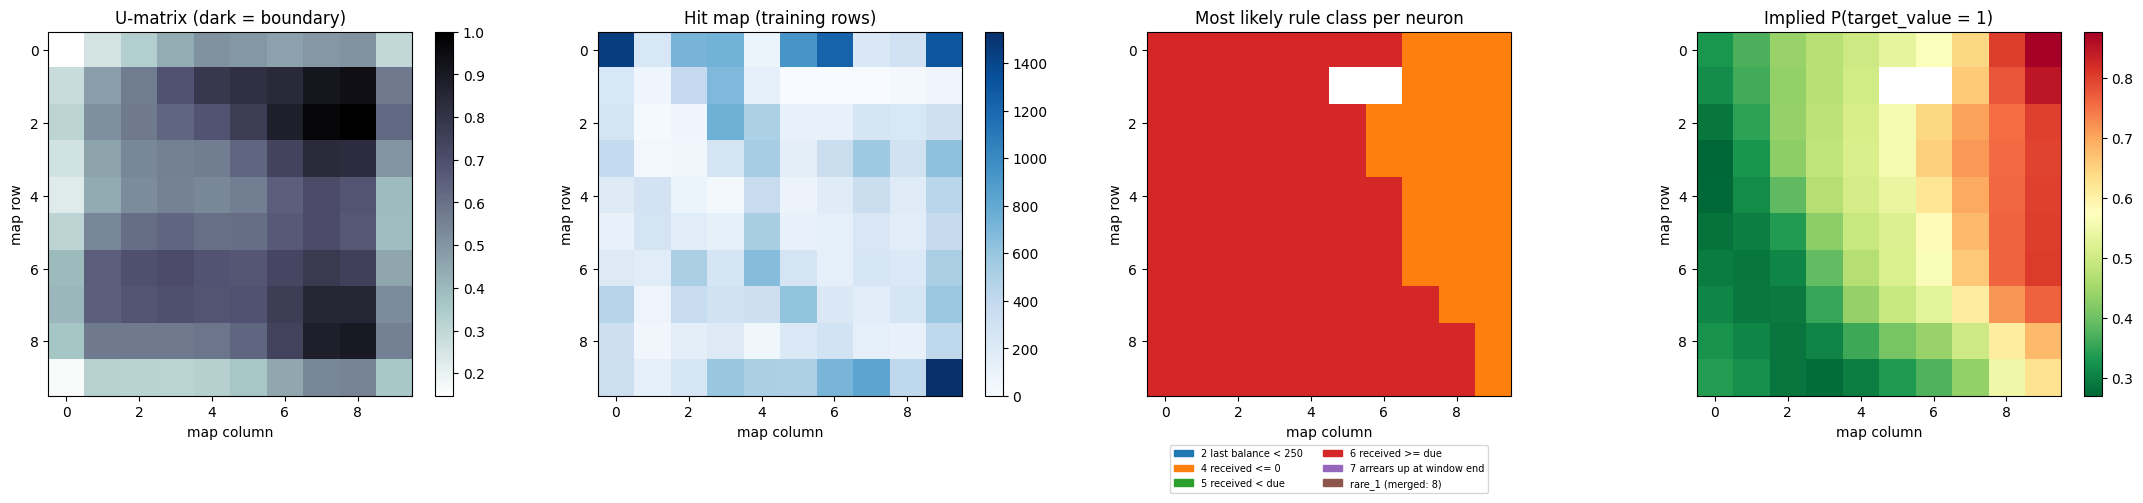

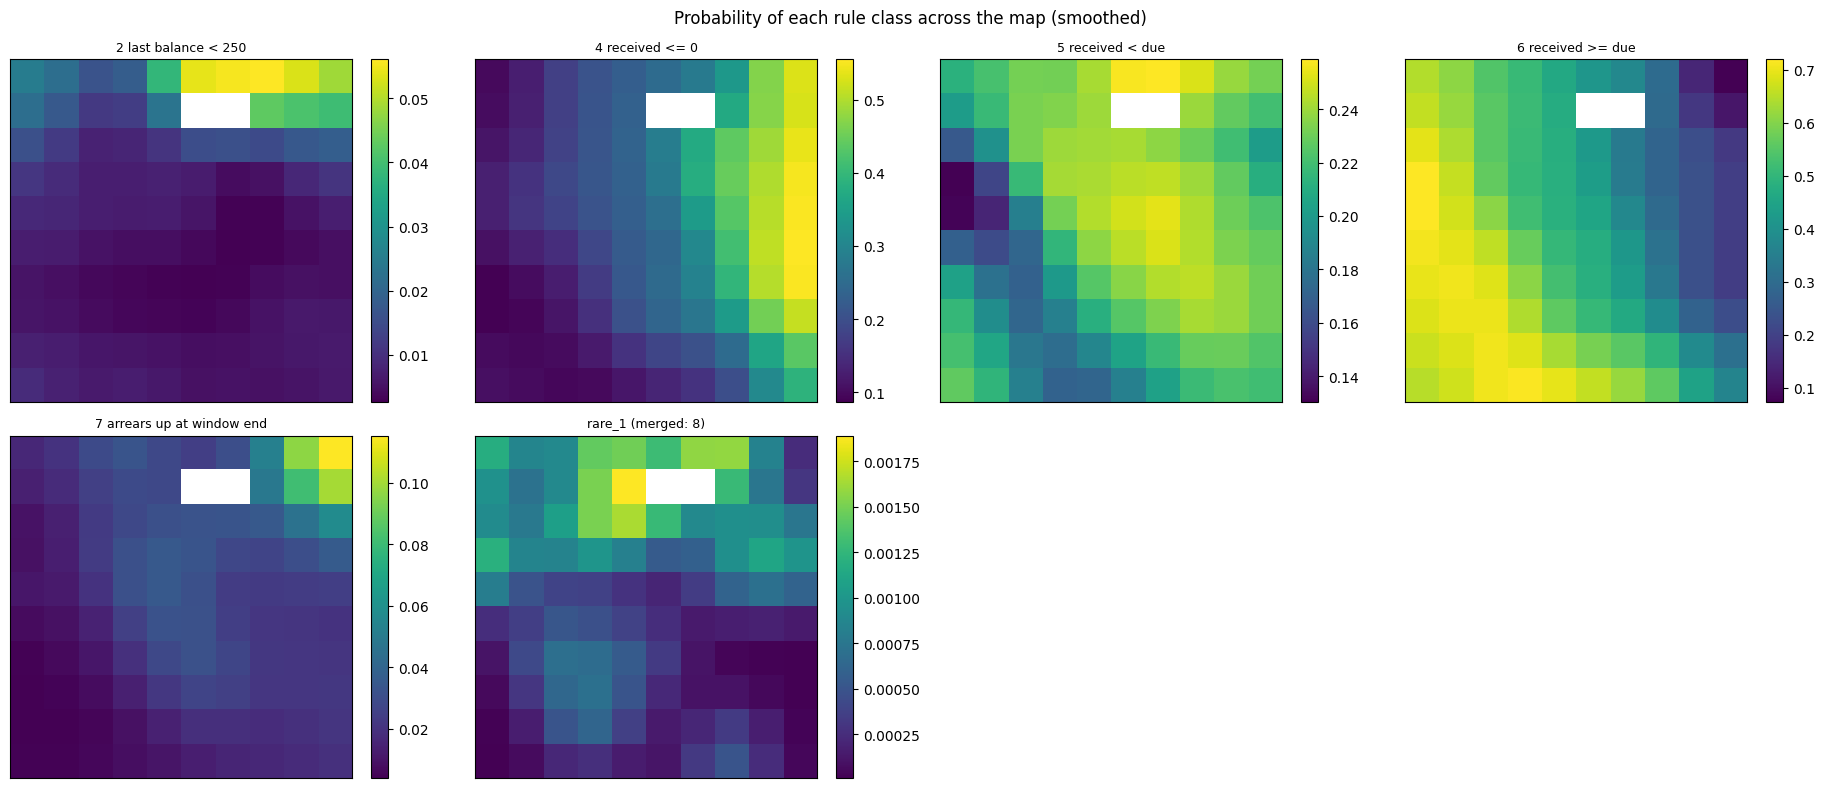

In [12]:
cmap = plt.get_cmap("tab10")
dom = P_neu.argmax(1).reshape(GRID)
fig, ax = plt.subplots(1, 4, figsize=(22, 5))
im = ax[0].imshow(som.distance_map(), cmap="bone_r"); ax[0].set_title("U-matrix (dark = boundary)"); plt.colorbar(im, ax=ax[0], fraction=0.046)
im = ax[1].imshow(hits, cmap="Blues"); ax[1].set_title("Hit map (training rows)"); plt.colorbar(im, ax=ax[1], fraction=0.046)
ax[2].imshow(np.ma.masked_where(hits == 0, dom), cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
ax[2].set_title("Most likely rule class per neuron"); ax[2].legend(handles=[Patch(color=cmap(i), label=class_name[i]) for i in range(C)], fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
p1 = np.ma.masked_where(hits == 0, P_neu[:, T1].sum(1).reshape(GRID))
im = ax[3].imshow(p1, cmap="RdYlGn_r"); ax[3].set_title("Implied P(target_value = 1)"); plt.colorbar(im, ax=ax[3], fraction=0.046)
for a in ax:
    a.set_xlabel("map column"); a.set_ylabel("map row")
plt.tight_layout(); plt.show()

ncol = 4; nrow = int(np.ceil(C / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 4 * nrow), squeeze=False)
for c, a in zip(range(C), axes.ravel()):
    im = a.imshow(np.ma.masked_where(hits == 0, P_neu[:, c].reshape(GRID)), cmap="viridis"); a.set_title(class_name[c], fontsize=9)
    a.set_xticks([]); a.set_yticks([]); plt.colorbar(im, ax=a, fraction=0.046)
for a in axes.ravel()[C:]:
    a.axis("off")
fig.suptitle("Probability of each rule class across the map (smoothed)"); plt.tight_layout(); plt.show()

### Component planes: what each region of the map means

Each panel is one feature's value across the map (standardised units, weights removed); the panels are the features that vary most across the occupied neurons. Compare them with the rule-class maps above: a feature whose pattern matches the region of a rule is what defines it.

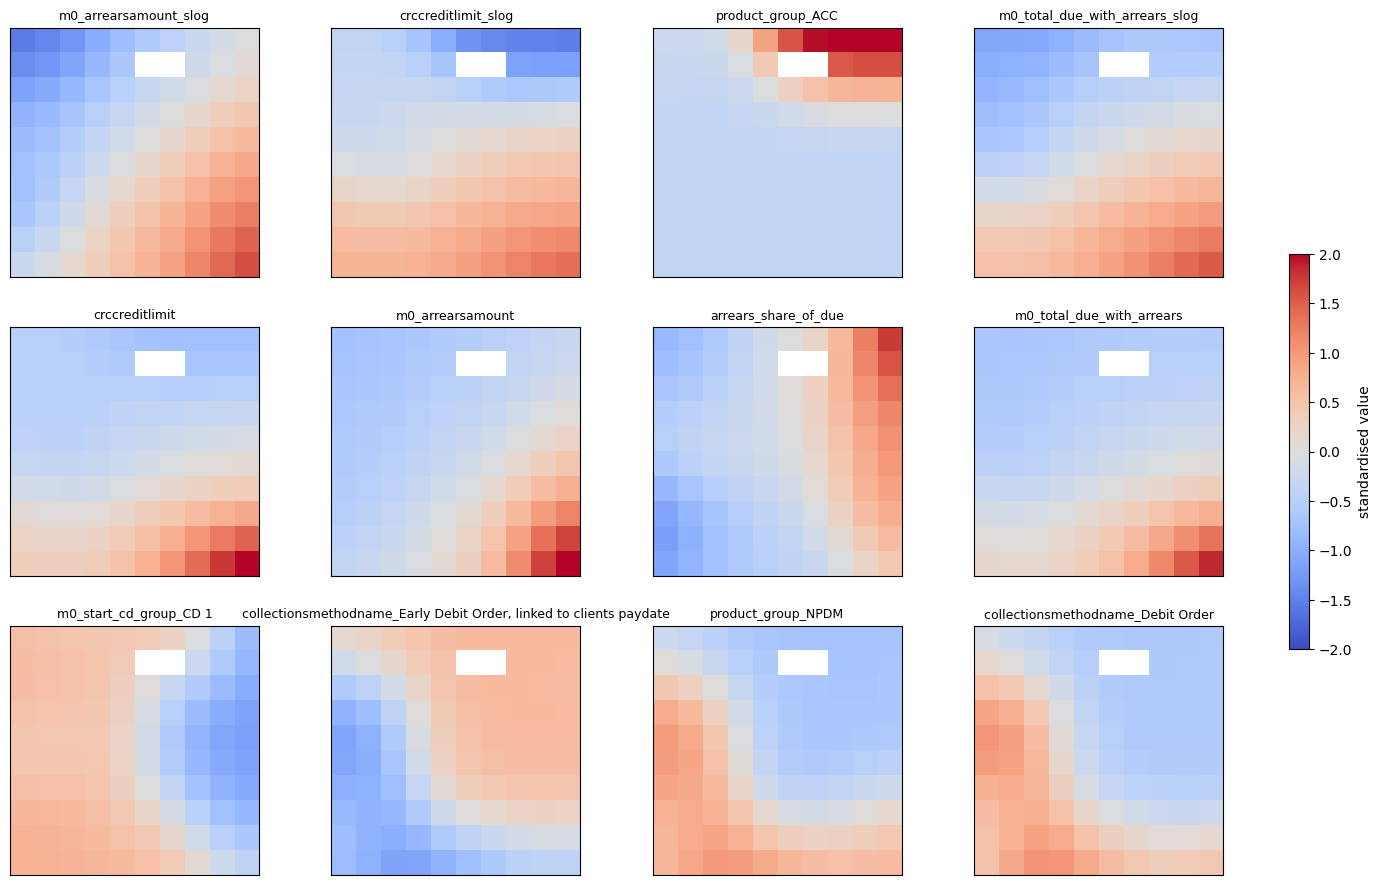

In [13]:
Wz = som.get_weights() / w
flat = Wz.reshape(-1, Wz.shape[2]); hw = hits.ravel() + 1e-9
mu = np.average(flat, axis=0, weights=hw)
spread = np.sqrt(np.average((flat - mu) ** 2, axis=0, weights=hw))
top = np.argsort(spread)[::-1][:12]
fig, axes = plt.subplots(3, 4, figsize=(17, 11))
for a, j in zip(axes.ravel(), top):
    im = a.imshow(np.ma.masked_where(hits == 0, Wz[:, :, j]), cmap="coolwarm", vmin=-2, vmax=2)
    a.set_title(X.columns[j], fontsize=9); a.set_xticks([]); a.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.015, label="standardised value"); plt.show()

### Macro-clusters, scored on the test rows

/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


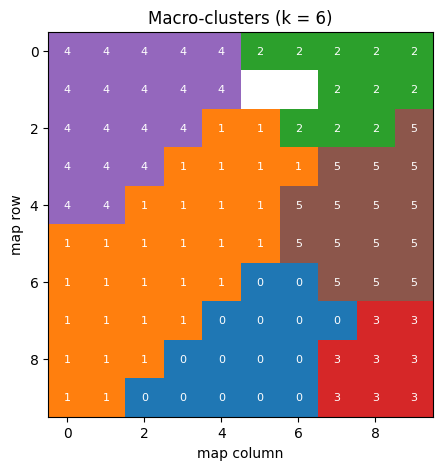

/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ 

,mc_logloss,mc_auc,bin_logloss,bin_auc,nmi,min_share
SOM macro-clusters,1.1271,0.5673,0.6485,0.6478,0.0431,0.1279
"K-means (same inputs, same k)",1.1307,0.5658,0.6513,0.6535,0.0424,0.0577
SOM neurons (10x10),1.0931,0.6283,0.6244,0.7034,NaN,NaN
no map,1.1890,0.5000,0.6924,0.5000,0.0000,NaN


In [14]:
cl = macro_labels(som, hits, K_MACRO)
lab_tr, lab_te = cl[btr], cl[bte]

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(np.ma.masked_where(hits == 0, cl.reshape(GRID)), cmap="tab10", vmin=0, vmax=9)
for i in range(GRID[0]):
    for j in range(GRID[1]):
        if hits[i, j] > 0:
            ax.text(j, i, cl.reshape(GRID)[i, j], ha="center", va="center", fontsize=8, color="white")
ax.set_title(f"Macro-clusters (k = {K_MACRO})"); ax.set_xlabel("map column"); ax.set_ylabel("map row"); plt.show()

km = KMeans(K_MACRO, n_init=10, random_state=RANDOM_STATE).fit(Ztr)
res = pd.DataFrame({
    "SOM macro-clusters": eval_labels(lab_tr, ytr, lab_te, yte, K_MACRO, prior_tr),
    "K-means (same inputs, same k)": eval_labels(km.labels_, ytr, km.predict(Zte), yte, K_MACRO, prior_tr),
    f"SOM neurons ({GRID[0]}x{GRID[1]})": {**res_neu, "nmi": np.nan, "min_share": np.nan},
    "no map": {**res_base, "nmi": 0.0, "min_share": np.nan}}).T
display(res.round(4))

The first two rows are the fair comparison (same number of segments, same inputs, same test rows). `mc_*` columns score the seven-way rule; `bin_*` columns score the derived binary target.

### What kind of outcome does each segment have?

Share of each rule class within every macro-cluster, on the test rows. This is the main explanatory table: for example a cluster dominated by rule 4 (no payment received) is a different kind of arrears risk from one dominated by rule 5 (partial payment) or rule 6 (paid in full).

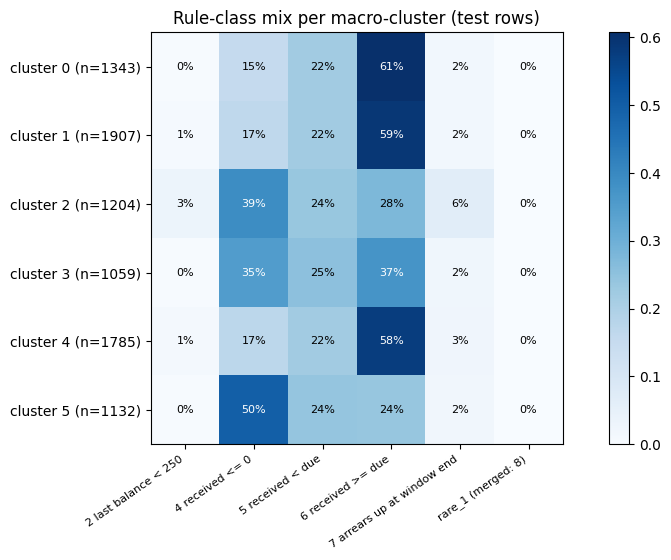

,n_test,share,most_likely_rule,p_target1_train,p_target1_test,ci_low,ci_high
c,,,,,,,
5,1132,0.134,4 received <= 0,0.755,0.759,0.733,0.783
2,1204,0.143,4 received <= 0,0.682,0.691,0.664,0.716
3,1059,0.126,6 received >= due,0.614,0.625,0.596,0.654
4,1785,0.212,6 received >= due,0.392,0.413,0.390,0.436
1,1907,0.226,6 received >= due,0.410,0.404,0.382,0.426
0,1343,0.159,6 received >= due,0.398,0.389,0.364,0.416


In [15]:
mix = pd.crosstab(lab_te, pd.Categorical.from_codes(yte, class_name), normalize="index")
n_te = pd.Series(lab_te).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(1.3 * C + 2, 0.7 * K_MACRO + 1.5))
im = ax.imshow(mix.to_numpy(), cmap="Blues", vmin=0, vmax=max(0.6, mix.to_numpy().max()))
ax.set_xticks(range(C)); ax.set_xticklabels(class_name, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(mix))); ax.set_yticklabels([f"cluster {c} (n={n_te[c]})" for c in mix.index])
for i in range(len(mix)):
    for j in range(C):
        ax.text(j, i, f"{mix.iloc[i, j]:.0%}", ha="center", va="center", fontsize=8, color="white" if mix.iloc[i, j] > 0.35 else "black")
ax.set_title("Rule-class mix per macro-cluster (test rows)"); plt.colorbar(im, ax=ax, fraction=0.03); plt.tight_layout(); plt.show()

def wilson(k, n, z=1.96):
    p = k / n; dd = 1 + z ** 2 / n; c = (p + z ** 2 / (2 * n)) / dd
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / dd
    return c - h, c + h

yb_te = class_target[yte]
t = pd.DataFrame({"c": lab_te, "y": yb_te}).groupby("c")["y"].agg(["sum", "count"])
lo, hi = wilson(t["sum"].to_numpy(), t["count"].to_numpy())
Pc = cluster_probs(lab_tr, ytr, K_MACRO, prior_tr)
seg = pd.DataFrame({"n_test": t["count"], "share": t["count"] / t["count"].sum(),
                    "most_likely_rule": [class_name[i] for i in Pc.argmax(1)[t.index]],
                    "p_target1_train": Pc[:, T1].sum(1)[t.index], "p_target1_test": t["sum"] / t["count"],
                    "ci_low": lo, "ci_high": hi}).sort_values("p_target1_test", ascending=False)
display(seg.round(3))

The intervals are 95% Wilson intervals on the derived binary target. A large gap between the train and test columns signals overfitting, most likely in small clusters.

### Feature profile of each segment (medians, original units)

In [16]:
med = X.loc[te_ids].assign(c=lab_te).groupby("c").median()
top_o = ((med.max() - med.min()) / X.loc[te_ids].std()).sort_values(ascending=False).head(15).index
display(med.loc[seg.index, top_o].T.round(2))

c,5,2,3,4,1,0
crccreditlimit_slog,9.26,6.91,10.62,8.41,9.26,10.13
product_group_ACC,0.00,1.00,0.00,0.00,0.00,0.00
m0_start_cd_group_CD 3,1.00,0.00,0.00,0.00,0.00,0.00
m0_arrearsamount_slog,7.20,6.30,8.29,5.58,6.47,7.31
m0_total_due_with_arrears_slog,8.02,7.21,9.30,6.93,7.85,8.66
"collectionsmethodname_Early Debit Order, linked to clients paydate",1.00,1.00,1.00,1.00,1.00,0.00
product_group_NPDM,0.00,0.00,1.00,0.00,0.00,1.00
m0_start_cd_group_CD 1,0.00,0.00,0.00,1.00,1.00,1.00
product_group_PDM,1.00,0.00,0.00,1.00,1.00,0.00
new_to_arrears_flag,0.00,0.00,0.00,1.00,1.00,1.00


### Stability

The map is retrained with different random seeds (random start, different sample order), the neurons are regrouped into the same number of macro-clusters, and the test-row labels are compared with the base run using the adjusted Rand index (ARI). About 0.7 or more is stable; below about 0.4 the segments depend on the seed.

In [17]:
rows = []
for s in range(1, 5):
    som_s = train_som(Ztr, GRID, seed=s, init="random")
    b_tr, _ = bmu_index(som_s, Ztr); b_te, _ = bmu_index(som_s, Zte)
    _, h_s = neuron_probs(b_tr, ytr, GRID)
    cl_s = macro_labels(som_s, h_s, K_MACRO, seed=s)
    r = eval_labels(cl_s[b_tr], ytr, cl_s[b_te], yte, K_MACRO, prior_tr)
    rows.append({"seed": s, "ARI_vs_base": adjusted_rand_score(lab_te, cl_s[b_te]), "mc_logloss": r["mc_logloss"], "mc_auc": r["mc_auc"], "nmi": r["nmi"]})
stab = pd.DataFrame(rows); display(stab.round(3)); print(stab["ARI_vs_base"].agg(["mean", "min"]).round(3).to_dict())

/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: divide by zero encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: overflow encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/var/folders/hr/h30nkl397gqb0sxzjgz_nvn00000gn/T/ipykernel_23640/3486004151.py:15: RuntimeWarning: invalid value encountered in matmul
  d2 = (z ** 2).sum(1)[:, None] - 2 * z @ W.T + w2[None, :]
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/hoyle/Documents/Uni/4th_Year/Methods

,seed,ARI_vs_base,mc_logloss,mc_auc,nmi
0,1,0.721,1.127,0.578,0.044
1,2,0.755,1.125,0.565,0.044
2,3,0.649,1.128,0.564,0.042
3,4,0.670,1.131,0.565,0.041


{'mean': 0.699, 'min': 0.649}


## 7. Export

In [18]:
out = pd.concat([
    pd.DataFrame({"obs_id": tr_ids, "split": "train", "bmu": btr, "macro_cluster": lab_tr}),
    pd.DataFrame({"obs_id": te_ids, "split": "test",  "bmu": bte, "macro_cluster": lab_te})], ignore_index=True)
out["map_row"], out["map_col"] = out["bmu"] // GRID[1], out["bmu"] % GRID[1]
out["target_rule"] = out["obs_id"].map(rule).to_numpy()
out["target_value"] = out["obs_id"].map(ybin).to_numpy()
out.drop(columns="bmu").to_csv("som_clustering_target_rule_no_time_aware/som_rule_assignments.csv", index=False)
mix.to_csv("som_clustering_target_rule_no_time_aware/som_rule_mix_per_cluster.csv"); seg.to_csv("som_clustering_target_rule_no_time_aware/som_rule_segment_profiles.csv"); div.to_csv("som_clustering_target_rule_no_time_aware/som_rule_class_diversity.csv")
print(f"Saved {len(out):,} assignments to som_clustering_target_rule_no_time_aware/som_rule_assignments.csv")

Saved 41,953 assignments to som_clustering_target_rule_no_time_aware/som_rule_assignments.csv
